# CNN Final: clasificador de huevos 


**Modelo.** Una CNN pequeña entrenada desde cero  que recibe el recorte de un huevo y dice si es *Ascaris*, uncinaria (*hookworm*) o *Trichuris*. Es la configuración ganadora de la búsqueda de `cnn_base.ipynb`  y `cnn_combos.ipynb`. Aquí se reentrena con 100 épocas y 3 semillas.

## Reglas


- Las fotos externas son solo de evaluación: nunca se usan para entrenar ni para elegir hiperparámetros.
- Los números salen de la corrida; en este texto no hay ninguno inventado.
- El sistema es un apoyo, nunca un diagnóstico.

In [1]:
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.patches import Rectangle
from PIL import Image, ImageEnhance, ImageFilter, ImageOps
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from ultralytics import YOLO

## 1. Parámetros

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
CROPS_CSV = ROOT / 'data/crops/crops.csv'
OUT_DIR = ROOT / 'dl/outputs/cnn_final'
COMBOS_DIR = ROOT / 'dl/outputs/cnn_combos'
ROUND1_DIR = ROOT / 'dl/outputs/cnn'
EXTERNAL_DIR = ROOT / 'data' / 'external_fov'   # photos cropped to the microscope field (data_prep/src/crop_field_of_view.py); the originals are in data/external
EXTERNAL_CSV = EXTERNAL_DIR / 'external.csv'
DETECTOR_WEIGHTS = ROOT / 'dl/outputs/yolo/yolo_1class_aug/weights/best.pt'   # 1-class YOLO, with augmentation
IMAGE_SUFFIXES = ('.jpg', '.jpeg', '.png', '.bmp')
CLASSES = ['ascaris', 'hookworm', 'trichuris']

TRAINING = False         
FINAL_TEST = False      
SEEDS = [42, 43, 44]    


CFG = dict(blocks=5, width=32, residual=False, dropout=0.3, lr=3e-4, aug='mid')
EPOCHS = 100             
PATIENCE = 20           
BATCH = 32
IMG_SIZE = 224
WEIGHT_DECAY = 1e-2
LABEL_SMOOTHING = 0.1
TRAIN_EVAL_SIZE = 500    
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

MARGIN = 0.15            
CONF_THRESHOLD = 0.25    
CONF_LOWEST = 0.001
MAX_BOXES_PER_PHOTO = 50

REFERENCE_40 = COMBOS_DIR / 'lr3e-4_b5'
EXISTING = {}

def run_dir(seed):
    return EXISTING.get(seed, OUT_DIR / f'seed{seed}')


DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_WORKERS = min(8, len(os.sched_getaffinity(0)))
print('device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'cpu', '| workers:', NUM_WORKERS)
assert CROPS_CSV.is_file(), f'missing {CROPS_CSV}: run data_prep/src/crop_eggs.py first'
assert EXTERNAL_DIR.is_dir(), f'missing {EXTERNAL_DIR}'
print('external photos:', EXTERNAL_DIR)


device: NVIDIA H100 NVL | workers: 8
external photos: /home/scar-test/deep-learning/data/external_fov


## 2. Configuración y cómo se llegó a ella

**Arquitectura.** Es una CNN pequeña entrenada **desde cero** (sin pesos preentrenados), con 4.715.747 parámetros (~19 MB en float32). Recibe el recorte de un huevo de 224 × 224 y devuelve la probabilidad de cada especie (*Ascaris*, uncinaria y *Trichuris*). Se compone de:

- **5 bloques convolucionales.** Cada uno aplica dos veces *convolución 3 × 3 → BatchNorm → ReLU* y termina con un *max pooling* de 2 × 2 que reduce la imagen a la mitad. Los canales se duplican en cada bloque (32, 64, 128, 256 y 512), de modo que la red empieza viendo bordes y texturas simples y termina con características más complejas, como la forma y la cubierta del huevo. Tras los 5 bloques, el mapa de características es de 7 × 7.
- **Cabeza de clasificación.** *Global average pooling* (promedia cada canal en un solo número), *dropout* de 0,3 y una capa lineal de 512 a 3 salidas.

La profundidad es de 10 capas convolucionales más la capa lineal final. El último bloque es el que usa Grad-CAM para mostrar qué zona del recorte mira la red.

Esta versión reentrena la configuración ganadora con 100 épocas y 3 semillas: 42, 43 y 44. Los resultados de la corrida de 40 épocas (`cnn_combos.ipynb`, semilla 42) se usan solo como referencia.

In [3]:
AUG = {
    'low': dict(color=0.1, blur=0.0, noise=0.0),
    'mid': dict(color=0.3, blur=0.3, noise=0.3),
    'high': dict(color=0.5, blur=0.5, noise=0.5),
}

search_rows = []
for round_name, base_dir in [('round 1 (25 epochs)', ROUND1_DIR), ('round 2 (40 epochs)', COMBOS_DIR)]:
    for done_path in sorted(base_dir.glob('*/done.json')):
        done = json.loads(done_path.read_text())
        cfg = json.loads((done_path.parent / 'config.json').read_text())
        search_rows.append({'round': round_name, 'run': done_path.parent.name, **cfg,
                            'best_val_f1': done['best_val_f1'], 'best_epoch': done['best_epoch']})
search = pd.DataFrame(search_rows)
if len(search):
    search = search.sort_values(['round', 'best_val_f1'], ascending=[True, False]).set_index(['round', 'run'])
search.round(4) if len(search) else 'no search results found'

blocks  width  residual  dropout      lr  \
round               run                                                       
round 1 (25 epochs) lr_3e-4             4     32     False      0.3  0.0003   
                    blocks_5            5     32     False      0.3  0.0010   
                    aug_low             4     32     False      0.3  0.0010   
                    residual            4     32      True      0.3  0.0010   
                    aug_mixup           4     32     False      0.3  0.0010   
                    base                4     32     False      0.3  0.0010   
                    dropout_0.5         4     32     False      0.5  0.0010   
                    aug_high            4     32     False      0.3  0.0010   
                    blocks_3            3     32     False      0.3  0.0010   
                    lr_3e-3             4     32     False      0.3  0.0030   
round 2 (40 epochs) lr3e-4_b5           5     32     False      0.3  0.0003   
                    lr3e-4_res_b5       5     32      True      0.3  0.0003   
                    lr1e-4_res_b5       5     32      True      0.3  0.0001   
                    ref_lr3e-4          4     32     False      0.3  0.0003   
                    lr3e-4_res          4     32      True      0.3  0.0003   

                                    aug  mixup  best_val_f1  best_epoch  
round               run                                                  
round 1 (25 epochs) lr_3e-4         mid  False       0.9027          20  
                    blocks_5        mid  False       0.8815          25  
                    aug_low         low  False       0.8402          22  
                    residual        mid  False       0.8027          23  
                    aug_mixup       mid   True       0.6863          23  
                    base            mid  False       0.6432          25  
                    dropout_0.5     mid  False       0.5637          24  
                    aug_high       high  False       0.5271          22  
                    blocks_3        mid  False       0.5233          25  
                    lr_3e-3         mid  False       0.4618           8  
round 2 (40 epochs) lr3e-4_b5       mid  False       0.9782          37  
                    lr3e-4_res_b5   mid  False       0.9709          27  
                    lr1e-4_res_b5   mid  False       0.9635          38  
                    ref_lr3e-4      mid  False       0.9562          36  
                    lr3e-4_res      mid  False       0.9317          37

## 3. Datos

- **Origen:** Chula-ParasiteEgg-11 (copia en Roboflow, CC BY 4.0), 3 clases. Un recorte por huevo (`data/crops/`), con 15 % de margen.
- **Split:** el del proyecto (70/15/15 por foto original, semilla 42). Esta red usa `train` para aprender y `valid` para elegir; `test` está congelado.
- **Preprocesamiento:** el recorte se rellena a **cuadrado** con su color medio (nunca se estira: la forma del huevo es lo que distingue la especie), se lleva a 224 × 224 y se normaliza con los valores de ImageNet. Es el mismo flujo de la rama ML y el que se aplica a cualquier foto externa.
- **Aumentos (solo en `train`):** rotaciones de 90° con espejo (un huevo no tiene arriba ni abajo; no se interpola nada), y según el nivel: variación de color y brillo, desenfoque gaussiano y ruido. Nivel `mid` = color 0,3, desenfoque con probabilidad 0,3 y ruido con probabilidad 0,3.
- **Limitación del EDA:** el fondo de la foto predice la especie (un random forest con solo el fondo llega a 0,635 de exactitud balanceada) y hay sesiones de captura repartidas entre `train` y `test`. Por eso `valid` puede dar números optimistas y lo que más pesa es lo externo (sección 11).

In [4]:
def pad_to_square(img):
    # Pad with the crop's mean color instead of stretching.
    side = max(img.size)
    fill = tuple(int(c) for c in np.asarray(img).reshape(-1, 3).mean(axis=0))
    return ImageOps.pad(img, (side, side), color=fill, centering=(0.5, 0.5))


def dihedral(img):
    # Random 90-degree rotation + optional mirror: the 8 symmetries of a square, nothing is interpolated.
    img = img.rotate(90 * random.randrange(4))
    return ImageOps.mirror(img) if random.random() < 0.5 else img


class AddNoise:
    def __init__(self, p, max_std=0.05):
        self.p, self.max_std = p, max_std

    def __call__(self, x):
        if random.random() < self.p:
            x = x + torch.randn_like(x) * random.uniform(0.01, self.max_std)
        return x.clamp(0, 1)


def make_transform(aug=None):
    steps = [T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BICUBIC)]
    if aug is not None:
        a = AUG[aug]
        steps += [
            T.Lambda(dihedral),
            T.ColorJitter(a['color'], a['color'], a['color'], a['color'] * 0.1),
            T.RandomApply([T.GaussianBlur(5, sigma=(0.5, 2.0))], p=a['blur']),
        ]
    steps.append(T.ToTensor())
    if aug is not None:
        steps.append(AddNoise(a['noise']))
    steps.append(T.Normalize(MEAN, STD))
    return T.Compose(steps)


class Crops(Dataset):
    def __init__(self, images, labels, aug=None):
        self.images, self.labels, self.tf = images, labels, make_transform(aug)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.tf(self.images[i]), self.labels[i]


df_all = pd.read_csv(CROPS_CSV)
df = df_all[df_all['split'].isin(['train', 'valid'])]   # test stays frozen unless FINAL_TEST is switched on
assert 'test' not in set(df['split'])


def load(frame):
    images = [pad_to_square(Image.open(ROOT / p).convert('RGB')) for p in frame['crop_path']]
    return images, [CLASSES.index(label) for label in frame['label']]


train_imgs, train_y = load(df[df['split'] == 'train'])
valid_frame = df[df['split'] == 'valid'].reset_index(drop=True)
valid_imgs, valid_y = load(valid_frame)
df.groupby(['split', 'label']).size().unstack()

label,ascaris,hookworm,trichuris
split,,,
train,636,650,638
valid,136,140,137


In [5]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_loader(images, labels, aug, shuffle, seed=42):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(Crops(images, labels, aug), batch_size=BATCH, shuffle=shuffle, drop_last=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE == 'cuda'),
                      persistent_workers=NUM_WORKERS > 0, generator=g)


# Fixed subset of train, without augmentation, to draw the train curves.
subset = np.random.RandomState(0).choice(len(train_y), TRAIN_EVAL_SIZE, replace=False)
train_eval_loader = make_loader([train_imgs[i] for i in subset], [train_y[i] for i in subset], None, shuffle=False)
valid_loader = make_loader(valid_imgs, valid_y, None, shuffle=False)

## 4. Arquitectura

Es una CNN sencilla de **5 bloques** apilados, con la estructura típica de las redes tipo VGG:

- **Bloque:** dos convoluciones 3×3 (cada una con BatchNorm; la primera con ReLU), un ReLU final y un `MaxPool` 2×2 que reduce la imagen a la mitad. Los canales se duplican en cada bloque (32, 64, 128, 256, 512). Con una entrada de 224 × 224, tras 5 reducciones queda un mapa de 7 × 7.
- **Cabeza:** promedio global (`AdaptiveAvgPool`) que resume cada canal en un número, `Dropout` (0,3) y una capa lineal de 512 a 3 salidas (una por especie).
- **Pérdida:** entropía cruzada con *label smoothing* 0,1. La salida se pasa por softmax para obtener una probabilidad por clase, que se usa como **confianza**.

**Por qué esta forma.** Las convoluciones 3×3 apiladas extraen rasgos de borde, textura y forma (el grosor de la cáscara, los tapones de *Trichuris*). BatchNorm estabiliza el entrenamiento desde cero. El promedio global evita una capa densa enorme y reduce el sobreajuste. Se probó con 3, 4 y 5 bloques: con 3 la red ve muy poco contexto y con 5 fue la mejor.



In [6]:
class Block(nn.Module):
    def __init__(self, cin, cout, residual):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout)) if residual else None
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        out = self.conv2(self.conv1(x))
        if self.skip is not None:
            out = out + self.skip(x)
        return self.pool(F.relu(out))


class CNN(nn.Module):
    def __init__(self, blocks, width, residual, dropout, n_classes=3):
        super().__init__()
        chans = [3] + [width * 2 ** i for i in range(blocks)]
        self.features = nn.Sequential(*[Block(chans[i], chans[i + 1], residual) for i in range(blocks)])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(chans[-1], n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def build_model(cfg):
    return CNN(cfg['blocks'], cfg['width'], cfg['residual'], cfg['dropout'])


arch_model = build_model(CFG)
print(arch_model)
per_block = {f'block {i + 1}': sum(p.numel() for p in b.parameters()) for i, b in enumerate(arch_model.features)}
per_block['head (linear)'] = sum(p.numel() for p in arch_model.head.parameters())
param_summary = pd.Series(per_block, name='parameters')
param_summary['total'] = param_summary.sum()
param_summary

CNN(
  (features): Sequential(
    (0): Block(
      (conv1): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv2): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Block(
      (conv1): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv2): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1),

block 1            10208
block 2            55552
block 3           221696
block 4           885760
block 5          3540992
head (linear)       1539
total            4715747
Name: parameters, dtype: int64

## 5. Entrenamiento

In [7]:
def evaluate(model, loader):
    model.eval()
    total, preds, ys = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            total += F.cross_entropy(out, y, reduction='sum').item()   # plain loss, no smoothing
            preds.append(out.argmax(1).cpu())
            ys.append(y.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return total / len(ys), preds, ys


def train_run(seed):
    out = run_dir(seed)
    if (out / 'done.json').is_file():
        print(f'seed {seed}: already trained, reused ({out})')
        return
    out.mkdir(parents=True, exist_ok=True)
    (out / 'config.json').write_text(json.dumps({**CFG, 'seed': seed}, indent=2))

    set_seed(seed)
    model = build_model(CFG).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    train_loader = make_loader(train_imgs, train_y, CFG['aug'], shuffle=True, seed=seed)

    history, best_f1, best_epoch, start = [], -1.0, 0, time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = crit(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()

        tr_loss, tr_pred, tr_true = evaluate(model, train_eval_loader)
        va_loss, va_pred, va_true = evaluate(model, valid_loader)
        row = dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss,
                   train_f1=f1_score(tr_true, tr_pred, average='macro'),
                   val_f1=f1_score(va_true, va_pred, average='macro'))
        history.append(row)
        if row['val_f1'] > best_f1:
            best_f1, best_epoch = row['val_f1'], epoch
            torch.save(model.state_dict(), out / 'best.pt')
        val_f1 = row['val_f1']
        minutes = (time.time() - start) / 60
        print(f'seed {seed} | epoch {epoch:2d}/{EPOCHS} | val F1 {val_f1:.4f} (best {best_f1:.4f}) | {minutes:.1f} min')
        if epoch - best_epoch >= PATIENCE:
            print(f'seed {seed}: early stop at epoch {epoch}')
            break

    pd.DataFrame(history).to_csv(out / 'history.csv', index=False)
    summary = dict(best_epoch=best_epoch, best_val_f1=best_f1, n_params=n_params, epochs_run=len(history),
                   minutes=round((time.time() - start) / 60, 2), device=DEVICE)
    (out / 'done.json').write_text(json.dumps(summary, indent=2))


if TRAINING:
    for seed in SEEDS:
        train_run(seed)
else:
    print('TRAINING = False: nothing is trained; the saved results are read')

for seed in SEEDS:
    for name in ('done.json', 'history.csv', 'best.pt'):
        assert (run_dir(seed) / name).is_file(), f'missing {run_dir(seed) / name}: set TRAINING = True to train seed {seed}'
    print(f'seed {seed}: artifacts found in {run_dir(seed)}')

TRAINING = False: nothing is trained; the saved results are read
seed 42: artifacts found in /home/scar-test/deep-learning/dl/outputs/cnn_final/seed42
seed 43: artifacts found in /home/scar-test/deep-learning/dl/outputs/cnn_final/seed43
seed 44: artifacts found in /home/scar-test/deep-learning/dl/outputs/cnn_final/seed44


## 6. Curvas, tiempo y sobreajuste

Las curvas de `train` se miden sobre 500 recortes **sin aumentos**, para que sean comparables con `valid`. La pérdida es la entropía cruzada normal (sin label smoothing). La línea punteada marca la mejor época.

**Cómo leerlas.** Si la pérdida de `valid` sube mientras la de `train` baja, hay sobreajuste. Si las dos siguen bajando al final, la red todavía estaba aprendiendo (subajuste).

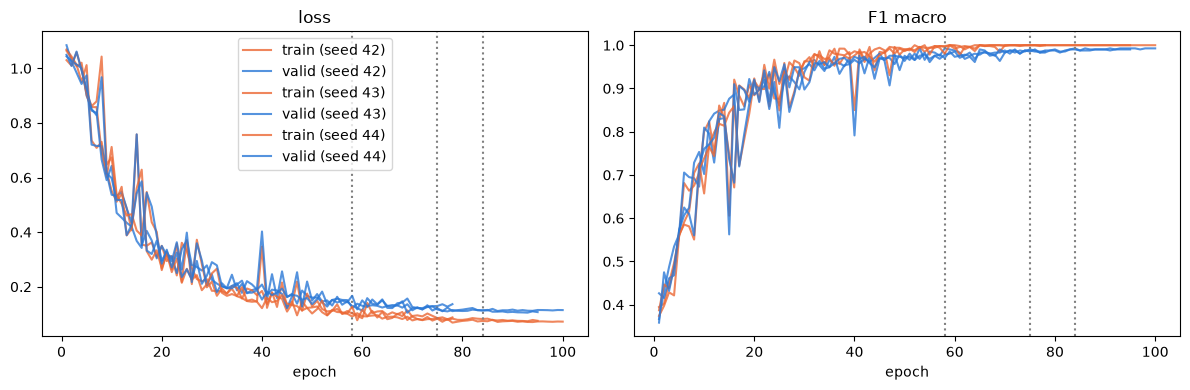

,best_epoch,epochs_run,minutes,device,n_params
42,58,78,2.58,cuda,4715747
43,75,95,3.08,cuda,4715747
44,84,100,3.23,cuda,4715747


In [8]:
histories = {seed: pd.read_csv(run_dir(seed) / 'history.csv') for seed in SEEDS}
dones = {seed: json.loads((run_dir(seed) / 'done.json').read_text()) for seed in SEEDS}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seed, h in histories.items():
    axes[0].plot(h['epoch'], h['train_loss'], color='#eb6834', alpha=0.8, label=f'train (seed {seed})')
    axes[0].plot(h['epoch'], h['val_loss'], color='#2a78d6', alpha=0.8, label=f'valid (seed {seed})')
    axes[1].plot(h['epoch'], h['train_f1'], color='#eb6834', alpha=0.8, label=f'train (seed {seed})')
    axes[1].plot(h['epoch'], h['val_f1'], color='#2a78d6', alpha=0.8, label=f'valid (seed {seed})')
    for ax in axes:
        ax.axvline(dones[seed]['best_epoch'], color='gray', ls=':')
axes[0].set(title='loss', xlabel='epoch')
axes[1].set(title='F1 macro', xlabel='epoch')
axes[0].legend()
plt.tight_layout()
plt.show()

pd.DataFrame(dones).T[['best_epoch', 'epochs_run', 'minutes', 'device', 'n_params']]

**Curvas de la corrida final (3 semillas, 100 épocas como máximo).** Las tres semillas se comportan casi igual, así que el resultado no depende de la semilla. La pérdida cae de ~1,1 a ~0,1 y el F1 macro sube de ~0,4 a ~0,99; después de la época ~60 las curvas casi se aplanan. Hay dos picos puntuales (épocas ~15 y ~40) de los que la red se recupera enseguida. En `train` el F1 llega a ~1,0 y en `valid` a ~0,99, y la pérdida de `valid` se mantiene plana (~0,11–0,12) sin subir: hay una brecha pequeña, no un sobreajuste fuerte. Las mejores épocas son la 58, la 75 y la 84; como el F1 está en una meseta, las diferencias entre épocas vecinas son mínimas. Las semillas 42 y 43 se detuvieron por parada temprana (en las épocas 78 y 95) y la 44 completó las 100. Cada entrenamiento tardó ~3 minutos en GPU.


In [9]:
overfit_rows = []
for seed, h in histories.items():
    best = dones[seed]['best_epoch']
    at_best, last = h.iloc[best - 1], h.iloc[-1]
    overfit_rows.append({'seed': seed, 'best_epoch': best, 'train_f1_at_best': at_best['train_f1'],
                         'val_f1_at_best': at_best['val_f1'], 'gap_at_best': at_best['train_f1'] - at_best['val_f1'],
                         'epoch_of_min_val_loss': int(h['val_loss'].idxmin()) + 1,
                         'val_loss_at_best': at_best['val_loss'], 'val_loss_last_epoch': last['val_loss']})
pd.DataFrame(overfit_rows).set_index('seed').round(4)

,best_epoch,train_f1_at_best,val_f1_at_best,gap_at_best,epoch_of_min_val_loss,val_loss_at_best,val_loss_last_epoch
seed,,,,,,,
42,58,0.9961,0.9927,0.0034,72,0.1242,0.1361
43,75,1.0000,0.9902,0.0098,69,0.1166,0.1070
44,84,1.0000,0.9927,0.0073,76,0.1134,0.1144


## 7. Métricas en `valid`

F1 macro (promedio de las tres clases, todas pesan igual), exactitud y errores. Con varias semillas, se agregan la media y la desviación. Más abajo, la precisión, el recall y el F1 por clase, y un intervalo de 95 % por *bootstrap* (se remuestrea `valid` 1000 veces) para saber cuánta incertidumbre tiene el número.

In [10]:
def predict_probs(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            probs.append(F.softmax(model(x.to(DEVICE)), 1).cpu())
            ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


def load_model(seed):
    model = build_model(CFG).to(DEVICE)
    model.load_state_dict(torch.load(run_dir(seed) / 'best.pt', map_location=DEVICE))
    return model.eval()


models = {seed: load_model(seed) for seed in SEEDS}
valid_probs, rows = {}, []
for seed, model in models.items():
    probs, valid_true = predict_probs(model, valid_loader)
    valid_probs[seed] = probs
    pred = probs.argmax(1)
    rows.append({'seed': seed, 'accuracy': accuracy_score(valid_true, pred),
                 'f1_macro': f1_score(valid_true, pred, average='macro'), 'errors': int((pred != valid_true).sum())})
valid_table = pd.DataFrame(rows).set_index('seed')
if len(SEEDS) > 1:
    per_seed = valid_table.copy()
    valid_table.loc['mean'] = per_seed.mean()
    valid_table.loc['std'] = per_seed.std()
valid_table.round(4)

/scratch/scar-test/job_29703/ipykernel_1177206/2308355546.py:28: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  valid_table.loc['mean'] = per_seed.mean()


,accuracy,f1_macro,errors
seed,,,
42,0.9927,0.9927,3.0000
43,0.9903,0.9902,4.0000
44,0.9927,0.9927,3.0000
mean,0.9919,0.9919,3.3333
std,0.0014,0.0014,0.5774


 El F1 macro es 0,9927, 0,9902 y 0,9927 para las semillas 42, 43 y 44 (media 0,9919, desviación 0,0014), con 3, 4 y 3 errores respectivamente. Es decir, las semillas se diferencian en un solo recorte (cada error equivale a ~0,0024), y el resultado es estable. La exactitud coincide con el F1 macro porque las clases están balanceadas. Frente a la ronda 2 (misma configuración, 40 épocas y una semilla: 0,9782, 9 errores), entrenar 100 épocas reduce los errores a poco más de la tercera parte. Con solo 3 semillas la desviación es una estimación aproximada, por lo que conviene reportar el rango (0,990–0,993). Estos valores pueden ser algo optimistas: la mejor época se elige con este mismo `valid`, y `valid` proviene de la misma fuente que `train`. La prueba que más pesa es la de las fotos externas (sección 11).


In [11]:
ref_path = REFERENCE_40 / 'done.json'
if ref_path.is_file():
    ref_done = json.loads(ref_path.read_text())
    ref_f1 = ref_done['best_val_f1']
    ref_epoch = ref_done['best_epoch']
    print(f'40-epoch reference (seed 42): val F1 {ref_f1:.4f}, best epoch {ref_epoch} of 40')
    now = valid_table.loc[SEEDS, 'f1_macro']
    print(f'this run ({EPOCHS} epochs), val F1 per seed: ' + ', '.join(f'{s}: {v:.4f}' for s, v in now.items()))
else:
    print('no 40-epoch reference found')

40-epoch reference (seed 42): val F1 0.9782, best epoch 37 of 40
this run (100 epochs), val F1 per seed: 42: 0.9927, 43: 0.9902, 44: 0.9927


In [12]:
main_seed = SEEDS[0]
main_pred = valid_probs[main_seed].argmax(1)
print(f'per-class report and interval below use seed {main_seed}')
report = pd.DataFrame(classification_report(valid_true, main_pred, target_names=CLASSES, output_dict=True)).T
display(report.round(4))

rng = np.random.default_rng(42)
boots = []
for _ in range(1000):
    idx = rng.integers(0, len(valid_true), len(valid_true))
    boots.append((f1_score(valid_true[idx], main_pred[idx], average='macro'), accuracy_score(valid_true[idx], main_pred[idx])))
ci = pd.DataFrame(np.percentile(np.array(boots), [2.5, 97.5], axis=0), index=['low', 'high'], columns=['f1_macro', 'accuracy'])
print('95% bootstrap interval on valid:')
ci.round(4)

per-class report and interval below use seed 42


,precision,recall,f1-score,support
ascaris,0.9926,0.9853,0.9889,136.0000
hookworm,0.9929,1.0000,0.9964,140.0000
trichuris,0.9927,0.9927,0.9927,137.0000
accuracy,0.9927,0.9927,0.9927,0.9927
macro avg,0.9927,0.9927,0.9927,413.0000
weighted avg,0.9927,0.9927,0.9927,413.0000


95% bootstrap interval on valid:


,f1_macro,accuracy
low,0.9848,0.9855
high,1.0000,1.0000


**Reporte de clasificación en `valid`.** Las tres especies quedan entre 0,989 y 0,996 de F1: ascaris 0,9889 (precisión 0,9926, recall 0,9853), hookworm 0,9964 (0,9929 y 1,0000) y trichuris 0,9927 (0,9927 y 0,9927). Hookworm es la clase mejor resuelta (los 140 huevos se encuentran) y ascaris la más débil (2 de 136 mal clasificados). La exactitud es 0,9927 (410 de 413) y el promedio macro coincide con el ponderado porque las clases están balanceadas. El intervalo bootstrap del 95 % es [0,9848; 1,0000] para el F1 macro y [0,9855; 1,0000] para la exactitud: el límite superior de 1,0000 aparece porque con solo 3 errores algunas remuestras no tienen ninguno, así que lo informativo es el límite inferior (~0,985). Es un intervalo sobre `valid`, que proviene de la misma fuente que `train`, por lo que no cubre el cambio a fotos externas.


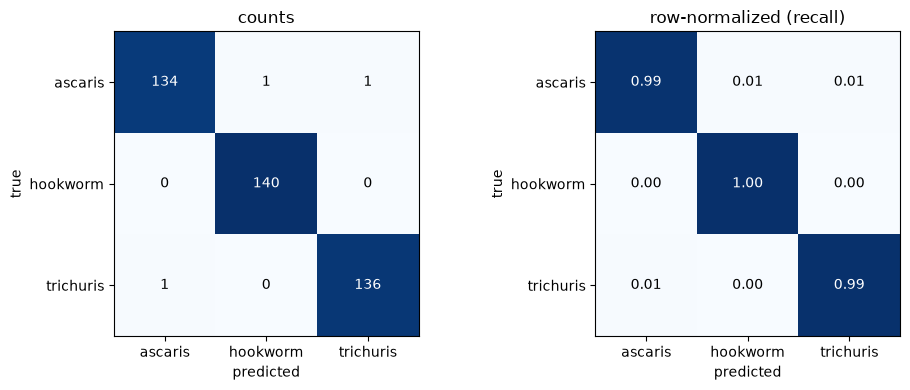

In [13]:
cm = confusion_matrix(valid_true, main_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, data, fmt) in zip(axes, [('counts', cm, '{:d}'), ('row-normalized (recall)', cm_norm, '{:.2f}')]):
    ax.imshow(data, cmap='Blues')
    ax.set(title=title, xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel='predicted', ylabel='true')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(data[i, j]), ha='center', va='center',
                    color='white' if data[i, j] > data.max() * 0.6 else 'black')
plt.tight_layout()
plt.show()

## 8. Confianza y rechazo

In [14]:
confidence = valid_probs[main_seed].max(1)
correct = main_pred == valid_true
print(f'mean confidence, correct: {confidence[correct].mean():.3f}')
if (~correct).any():
    print(f'mean confidence, wrong:   {confidence[~correct].mean():.3f}')

reject_rows = []
for threshold in [0.0, 0.5, 0.7, 0.9, 0.95, 0.99]:
    keep = confidence >= threshold
    reject_rows.append({'threshold': threshold, 'coverage': keep.mean(),
                        'accuracy_on_accepted': correct[keep].mean() if keep.any() else np.nan})
pd.DataFrame(reject_rows).set_index('threshold').round(4)

mean confidence, correct: 0.899
mean confidence, wrong:   0.604


,coverage,accuracy_on_accepted
threshold,,
0.00,1.0000,0.9927
0.50,0.9903,0.9951
0.70,0.9298,0.9974
0.90,0.6586,1.0000
0.95,0.3850,1.0000
0.99,0.0169,1.0000


**Confianza y rechazo (`valid`, semilla 42).** Si solo se aceptan los recortes cuya confianza supera un umbral, el acierto sube a costa de revisar más recortes a mano. Con umbral 0,50 se aceptan el 99,0 % de los recortes (acierto 0,9951); con 0,70, el 93,0 % (0,9974); con 0,90, el 65,9 % (1,0000). Los 3 errores de `valid` tienen confianza menor que 0,90, por lo que la confianza es informativa: la red duda justo cuando se equivoca. Un umbral de 0,70 elimina 2 de los 3 errores rechazando solo ~7 % de los recortes, y 0,90 elimina todos pero deja un tercio para revisión. Con umbrales de 0,95 o más la cobertura cae a 38,5 % y 1,7 %, probablemente porque el label smoothing de 0,1 impide que la red dé probabilidades cercanas a 1; son umbrales poco útiles para esta red. Con tan pocos errores, las diferencias de acierto entre umbrales son de uno o dos recortes. Esto es sobre `valid`; en las fotos externas la confianza suele ser menor, por lo que el umbral debe revisarse allí antes de fijarlo.


## 9. Errores e interpretabilidad (Grad-CAM)

Primero los recortes que la red clasifica mal en `valid`, con la especie real, la predicha y la confianza. Después **Grad-CAM**: un mapa de calor de las zonas de la imagen que más pesaron en la decisión de la red (rojo = más importante). Sirve para ver si mira el huevo o el fondo. Se muestra un acierto por especie y los primeros errores.

Grad-CAM sale de la última convolución, de 7 × 7, y se estira a 224 × 224, así que es un mapa grueso. El PLAN pide que un parasitólogo de la UPB revise una muestra de aciertos y errores.

,crop_path,label,predicted,confidence
27,data/crops/valid/ascaris/Ascaris-lumbricoides_...,ascaris,hookworm,0.395
120,data/crops/valid/ascaris/Ascaris-lumbricoides_...,ascaris,trichuris,0.661
304,data/crops/valid/trichuris/Trichuris-trichiura...,trichuris,ascaris,0.755


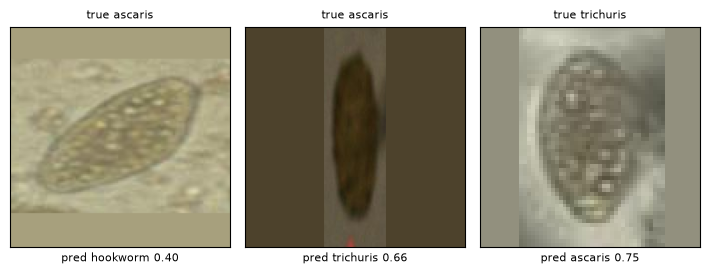

In [15]:
wrong_idx = np.where(~correct)[0]
errors = valid_frame.iloc[wrong_idx][['crop_path', 'label']].copy()
errors['predicted'] = [CLASSES[p] for p in main_pred[wrong_idx]]
errors['confidence'] = confidence[wrong_idx].round(3)
display(errors)

show = wrong_idx[:12]
fig, axes = plt.subplots(1, max(len(show), 1), figsize=(2.4 * max(len(show), 1), 3), squeeze=False)
for ax, i in zip(axes[0], show):
    ax.imshow(valid_imgs[i])
    ax.set_title(f'true {CLASSES[valid_true[i]]}', fontsize=8)
    ax.set_xlabel(f'pred {CLASSES[main_pred[i]]} {confidence[i]:.2f}', fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

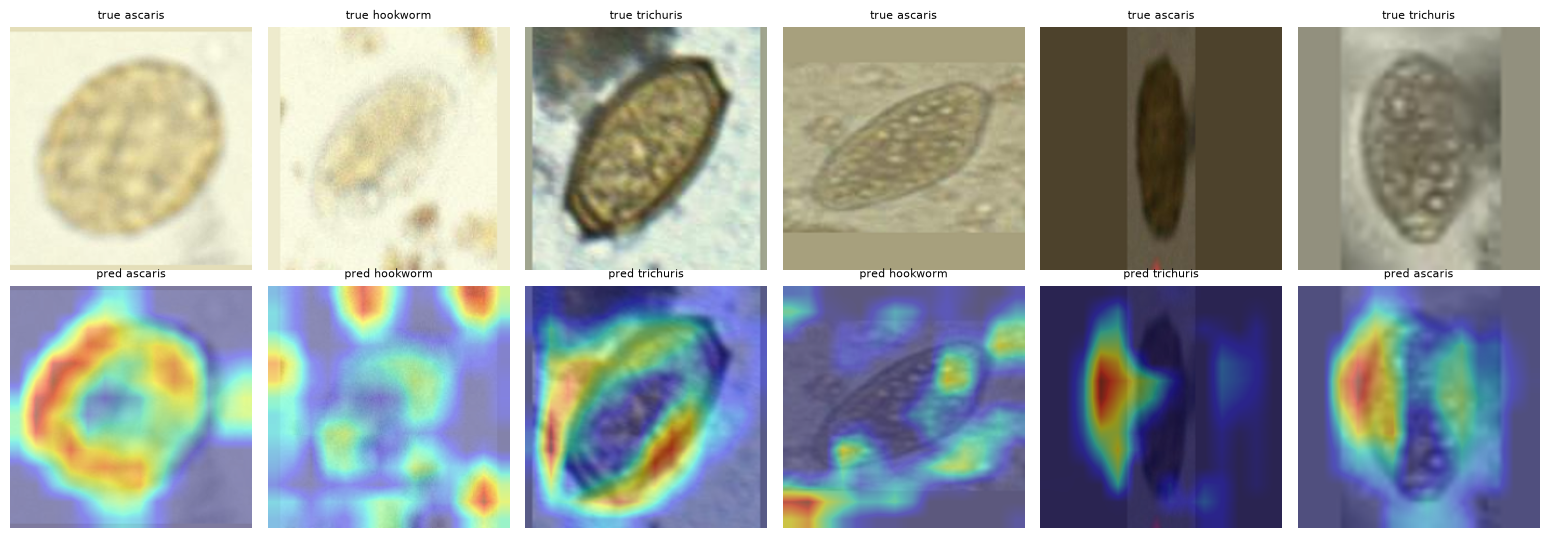

In [16]:
def grad_cam(model, x):
    """Heat map (224x224, 0..1) of the class the model predicts for the single image x (1, 3, H, W)."""
    store = {}
    layer = model.features[-1].conv2

    def save_output(module, inputs, output):
        store['a'] = output
        output.retain_grad()

    handle = layer.register_forward_hook(save_output)
    model.eval()
    out = model(x)
    target = int(out.argmax(1).item())
    model.zero_grad()
    out[0, target].backward()
    handle.remove()
    a = store['a']
    weights = a.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * a).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), target


def denormalize(x):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (x.detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


eval_tf = make_transform(None)
examples = []
for c in range(3):
    ok = np.where(correct & (valid_true == c))[0]
    if len(ok):
        examples.append(int(ok[np.argmax(confidence[ok])]))
examples += [int(i) for i in wrong_idx[:3]]

fig, axes = plt.subplots(2, len(examples), figsize=(2.6 * len(examples), 5.4), squeeze=False)
for col, i in enumerate(examples):
    x = eval_tf(valid_imgs[i]).unsqueeze(0).to(DEVICE)
    cam, target = grad_cam(models[main_seed], x)
    img = denormalize(x[0])
    axes[0, col].imshow(img)
    axes[0, col].set_title(f'true {CLASSES[valid_true[i]]}', fontsize=8)
    axes[1, col].imshow(img)
    axes[1, col].imshow(cam, cmap='jet', alpha=0.45)
    axes[1, col].set_title(f'pred {CLASSES[target]}', fontsize=8)
    axes[0, col].axis('off')
    axes[1, col].axis('off')
plt.tight_layout()
plt.show()

## 10. Recursos

Qué tan pesada y rápida es la red. La latencia se mide en **CPU**, un recorte a la vez como lo haría la app en la laptop de campo. Se mide en la máquina donde corre el notebook, que no es la laptop de campo: sirve de referencia, no como cifra final.

In [17]:
cpu_model = build_model(CFG)
cpu_model.load_state_dict(torch.load(run_dir(main_seed) / 'best.pt', map_location='cpu'))
cpu_model.eval()
sample = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    for _ in range(5):
        cpu_model(sample)
    start = time.perf_counter()
    for _ in range(30):
        cpu_model(sample)
latency_ms = (time.perf_counter() - start) / 30 * 1000
n_params = sum(p.numel() for p in cpu_model.parameters())

pd.Series({
    'parameters': n_params,
    'size_MB_float32': round(n_params * 4 / 1e6, 1),
    'cpu_latency_ms_per_crop': round(latency_ms, 1),
    'cpu_threads': torch.get_num_threads(),
    'training_minutes': dones[main_seed]['minutes'],
    'training_device': dones[main_seed]['device'],
}, name='resources')

parameters                 4715747
size_MB_float32               18.9
cpu_latency_ms_per_crop       74.9
cpu_threads                      1
training_minutes              2.58
training_device               cuda
Name: resources, dtype: object

## 11. Fotos externas: YOLO + CNN

La prueba que más importa: fotos que **no** vienen de Chula (celular por el ocular). El flujo es el del sistema completo:

1. El **detector YOLO de 1 clase** (`DETECTOR_WEIGHTS`) encuentra los huevos en la foto.
2. Cada caja se **recorta** con 15 % de margen, igual que en el entrenamiento, y se rellena a cuadrado.
3. La **CNN** clasifica cada recorte y da su confianza.

Se usan las fotos con `uso = prueba` de `external.csv`; las de `uso = desarrollo` se muestran pero no cuentan (una se usó para diseñar los aumentos).

**Límites que hay que decir en el informe:**
- Son 98 fotos de prueba con 101 huevos, de **una sola fuente** (mismo microscopio y celular) y con algunos huevos fotografiados varias veces: es una señal, no una medida definitiva. Las fotos están recortadas al círculo del ocular (`data/external_fov/`); las fotos sin huevos (`Control/`) quedaron fuera por decisión del equipo.
- No hay cajas reales dibujadas: el conteo compara **cantidades** (`found = min(cajas, huevos reales)`), no ubicaciones, así que una caja mal puesta puede contar como acierto.
- Cada foto tiene una sola especie (la del nombre del archivo). Una caja cuenta como acierto de especie si la CNN predice esa especie; una falsa alarma que adivine la especie podría contar como acierto, por eso `species_ok` es una cota aproximada.

In [18]:
external_photos = pd.read_csv(EXTERNAL_CSV)
photos_on_disk = {p.name for p in EXTERNAL_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES}
assert photos_on_disk == set(external_photos.image), 'fix external.csv first'
external_photos['n_items'] = external_photos.n_items.astype(int)
test_photos = external_photos[external_photos.uso == 'prueba']
print(f'{len(test_photos)} test photos with {test_photos.n_items.sum()} eggs')

assert DETECTOR_WEIGHTS.is_file(), f'missing detector weights: {DETECTOR_WEIGHTS}'
detector = YOLO(str(DETECTOR_WEIGHTS))
DET_DEVICE = 0 if DEVICE == 'cuda' else 'cpu'


def expand(box, margin, width, height):
    x1, y1, x2, y2 = box
    dw, dh = (x2 - x1) * margin, (y2 - y1) * margin
    return (max(0, int(round(x1 - dw))), max(0, int(round(y1 - dh))),
            min(width, int(round(x2 + dw))), min(height, int(round(y2 + dh))))


def classify(crops):
    x = torch.stack([eval_tf(pad_to_square(c)) for c in crops]).to(DEVICE)
    with torch.no_grad():
        return torch.stack([F.softmax(m(x), 1).cpu() for m in models.values()]).mean(0).numpy()


rows = []
for photo in external_photos.itertuples():
    path = EXTERNAL_DIR / photo.image
    img = ImageOps.exif_transpose(Image.open(path)).convert('RGB')  # upright: phone JPGs carry EXIF rotation and YOLO boxes are in the rotated frame
    width, height = img.size
    result = detector.predict(source=img, imgsz=640, conf=CONF_LOWEST, max_det=MAX_BOXES_PER_PHOTO,
                              device=DET_DEVICE, verbose=False)[0]
    crops, meta = [], []
    for box, score in zip(result.boxes.xyxy.tolist(), result.boxes.conf.tolist()):
        x1, y1, x2, y2 = expand(box, MARGIN, width, height)
        if min(x2 - x1, y2 - y1) < 16:
            continue
        crops.append(img.crop((x1, y1, x2, y2)))
        meta.append((box, score))
    if not crops:
        continue
    for (box, score), p in zip(meta, classify(crops)):
        rows.append({'image': photo.image, 'det_score': score, 'x1': box[0], 'y1': box[1], 'x2': box[2], 'y2': box[3],
                     'pred': CLASSES[int(p.argmax())], 'cnn_prob': float(p.max())})
external_dets = pd.DataFrame(rows, columns=['image', 'det_score', 'x1', 'y1', 'x2', 'y2', 'pred', 'cnn_prob'])
external_dets.groupby('image').size().rename('boxes found (any score)')

98 test photos with 101 eggs


image
a-image.png     2
a-image2.png    3
a-n001.jpg      1
a-n002.jpg      1
a-n003.jpg      1
               ..
t-n026.jpg      1
t-n027.jpg      1
t-n028.jpg      3
t-n029.jpg      1
t-n030.jpg      2
Name: boxes found (any score), Length: 99, dtype: int64

In [19]:
real = test_photos.set_index('image').n_items
species_of = external_photos.set_index('image').species


def external_summary(conf):
    kept = external_dets[(external_dets.det_score >= conf) & external_dets.image.isin(real.index)]
    boxes = kept.groupby('image').size().reindex(real.index, fill_value=0)
    found = np.minimum(boxes, real)
    right = kept[kept.pred == kept.image.map(species_of)].groupby('image').size().reindex(real.index, fill_value=0)
    return pd.DataFrame({'real_eggs': real, 'boxes': boxes, 'found': found, 'missed': real - found,
                         'false_alarms': boxes - found, 'species_ok': np.minimum(right, found)})


per_photo = external_summary(CONF_THRESHOLD)
per_photo.insert(0, 'species', species_of.reindex(per_photo.index))
per_photo.loc['total'] = per_photo.drop(columns='species').sum()
print(f'detector threshold {CONF_THRESHOLD}')
display(per_photo)

curve = pd.DataFrame({conf: external_summary(conf).sum() for conf in [0.05, 0.1, 0.25, 0.5, 0.75]}).T
curve.index.name = 'det_conf'
print('same totals at other detector thresholds')
curve

detector threshold 0.25


,species,real_eggs,boxes,found,missed,false_alarms,species_ok
image,,,,,,,
a-image.png,ascaris,2,2,2,0,0,1
h-image.png,hookworm,2,2,2,0,0,2
h-image2.png,hookworm,1,1,1,0,0,1
t-image.png,trichuris,2,1,1,1,0,1
t-image2.png,trichuris,1,1,1,0,0,1
...,...,...,...,...,...,...,...
h-n029.jpg,hookworm,1,2,1,0,1,1
h-n030.jpg,hookworm,1,2,1,0,1,1
h-n031.jpg,hookworm,1,1,1,0,0,1


same totals at other detector thresholds


,real_eggs,boxes,found,missed,false_alarms,species_ok
det_conf,,,,,,
0.05,101,118,101,0,17,95
0.10,101,114,101,0,13,95
0.25,101,108,100,1,8,94
0.50,101,105,100,1,5,94
0.75,101,93,91,10,2,87


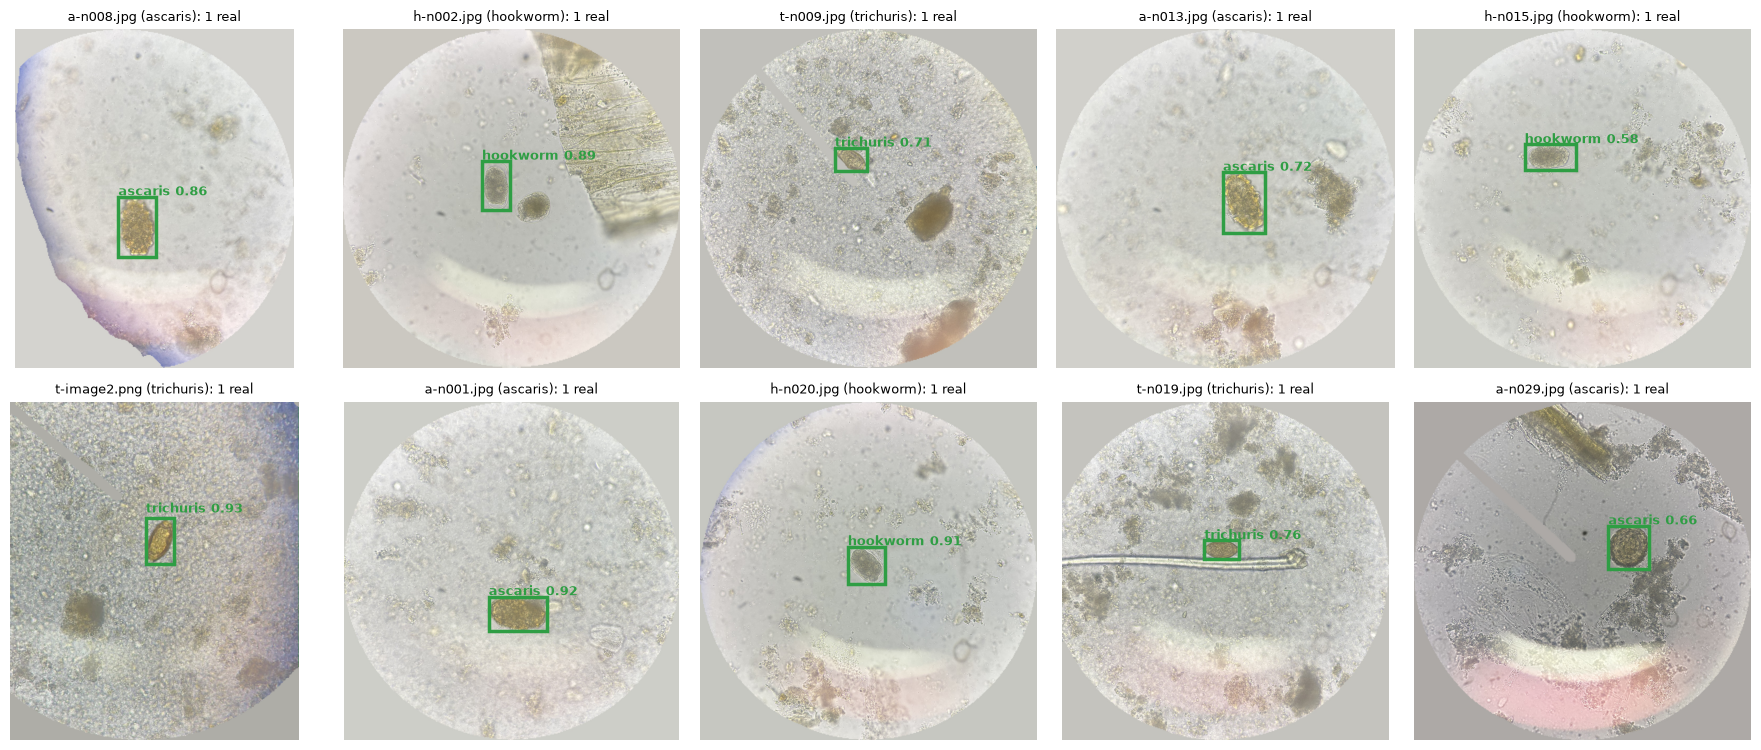

In [20]:
N_SHOW, N_COLS = 10, 5

rng = np.random.default_rng(42)
pool = external_photos[external_photos.uso == 'prueba'].copy()
pool['group'] = pool.species.fillna('control')
groups = {g: list(rng.permutation(df.image.values)) for g, df in pool.groupby('group')}
chosen = []
while len(chosen) < N_SHOW and any(groups.values()):
    for g in groups:
        if groups[g] and len(chosen) < N_SHOW:
            chosen.append(groups[g].pop())
sample = external_photos.set_index('image').loc[chosen].reset_index()

shown = external_dets[external_dets.det_score >= CONF_THRESHOLD]
n_rows = int(np.ceil(len(sample) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.6 * N_COLS, 3.8 * n_rows), squeeze=False)
for ax in axes.ravel():
    ax.axis('off')
for ax, photo in zip(axes.ravel(), sample.itertuples()):
    ax.imshow(ImageOps.exif_transpose(Image.open(EXTERNAL_DIR / photo.image)))
    for box in shown[shown.image == photo.image].itertuples():
        color = '#2f9e44' if box.pred == photo.species else '#d62828'
        ax.add_patch(Rectangle((box.x1, box.y1), box.x2 - box.x1, box.y2 - box.y1,
                               fill=False, edgecolor=color, linewidth=2.5))
        ax.text(box.x1, box.y1 - 10, f'{box.pred} {box.cnn_prob:.2f}', color=color, fontsize=9, fontweight='bold')
    ax.set_title(f'{photo.image} ({photo.species if isinstance(photo.species, str) else "control"}): {photo.n_items} real', fontsize=9)
plt.tight_layout()
plt.show()


**Resultado en fotos externas (YOLO 1 clase + conjunto de 3 CNN; 98 fotos de prueba recortadas al ocular, 101 huevos; detector a 0,25).** El detector encuentra 100 de los 101 huevos, con 108 cajas: 1 huevo perdido y 8 cajas de más. Las cajas de más incluyen huevos reales que no se contaron, porque se asumió un huevo por foto. La CNN acierta la especie en 94 de los 100 huevos encontrados (94 %); con otros umbrales del detector, entre 87 y 95 aciertos. Frente al F1 de `valid` (0,992), la caída es de unos 5 puntos: cumple el criterio del PLAN (máximo 10), pero es la mayor de los tres clasificadores. Sobre los mismos recortes, VGG16 y EfficientNet-B0 aciertan 99 y 98 de 100 (`comparison.ipynb`). Con la foto completa, sin recortar, el detector encuentra 93 huevos y la CNN acierta 85. `species_ok` es una cota aproximada: una caja de más que adivine la especie contaría como acierto. Nota de método: una versión anterior de este notebook reportaba 40 de 93 (43 %). Era un error de código: las fotos del iPhone traen rotación EXIF, y los recortes no coincidían con las cajas de YOLO. Ya está corregido.